# AlphaDesk — Insights notebook

Six data-backed findings from the ingested NAV history. Every number here comes from the same metrics module (`analytics/metrics.py`) and SQL files (`backend/sql/`) used by the API — this notebook is the readable, inspectable version. Pair with `INSIGHTS.md` for the "so what".

In [1]:
from __future__ import annotations
import sys, pathlib

# Make the backend importable regardless of where jupyter was started.
REPO_ROOT = pathlib.Path.cwd().resolve()
while REPO_ROOT != REPO_ROOT.parent and not (REPO_ROOT / 'backend' / 'app').exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / 'backend'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import select

from app.db import SessionLocal
from app.models import Fund
from analytics.loader import load_fund_nav, load_benchmark
from analytics.metrics import compute_scorecard, category_percentile_rank

pd.set_option('display.max_colwidth', 50)
pd.set_option('display.width', 160)
plt.rcParams.update({
    'figure.figsize': (9, 4),
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'font.size': 10,
})

Matplotlib is building the font cache; this may take a moment.


## Build the universe-wide scorecard once

In [2]:
rows = []
with SessionLocal() as s:
    bench_cache: dict = {}
    for f in s.scalars(select(Fund).order_by(Fund.category, Fund.scheme_code)).all():
        nav = load_fund_nav(s, f.scheme_code)
        bench = None
        if f.benchmark_id:
            bench_cache.setdefault(f.benchmark_id, load_benchmark(s, f.benchmark_id))
            if not bench_cache[f.benchmark_id].empty:
                bench = bench_cache[f.benchmark_id]
        sc = compute_scorecard(f.scheme_code, nav, bench)
        rows.append({
            'scheme_code': f.scheme_code,
            'name': f.name,
            'category': f.category,
            '1Y': sc.trailing['1Y'].value,
            '3Y': sc.trailing['3Y'].value,
            '5Y': sc.trailing['5Y'].value,
            'vol': sc.volatility.value,
            'max_dd': sc.max_drawdown.value,
            'sharpe': sc.sharpe.value,
            'beta': sc.beta.value,
            'alpha': sc.alpha.value,
        })
df = pd.DataFrame(rows)
df.shape

(29, 11)

## 1 — Three Nifty 50 index funds track within 6 bps

5Y CAGR spread between HDFC / UTI / Nippon India Nifty 50 index funds (Direct–Growth).

In [3]:
idx = df[df['category'] == 'index'].copy()
n50 = idx[idx['name'].str.contains('Nifty 50')].sort_values('5Y')
display(n50[['name', '5Y', 'vol', 'max_dd']].round(4))
spread_pp = (n50['5Y'].max() - n50['5Y'].min()) * 100
print(f'5Y CAGR spread among Nifty 50 index funds: {spread_pp:.3f} percentage points')

,name,5Y,vol,max_dd
5,HDFC Nifty 50 Index Fund - Direct Plan - Growth,0.0548,0.1601,-0.3836
6,UTI Nifty 50 Index Fund - Direct Plan - Growth,0.0553,0.1603,-0.3842
4,Nippon India Index Fund - Nifty 50 Plan - Dire...,0.0554,0.1595,-0.3817


5Y CAGR spread among Nifty 50 index funds: 0.061 percentage points


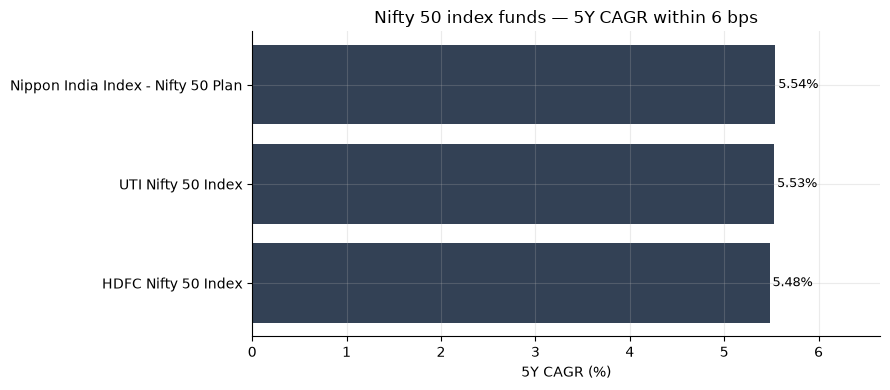

In [4]:
fig, ax = plt.subplots()
ax.barh(n50['name'].str.replace(' - Direct Plan - Growth', '').str.replace(' Fund', ''), n50['5Y'] * 100, color='#334155')
ax.set_xlabel('5Y CAGR (%)')
ax.set_title('Nifty 50 index funds — 5Y CAGR within 6 bps')
ax.set_xlim(0, max(n50['5Y']) * 100 * 1.2)
for i, v in enumerate(n50['5Y'] * 100):
    ax.text(v + 0.03, i, f'{v:.2f}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

## 2 — Parag Parikh Flexi Cap has ~2× the Sharpe of its peers

Flexi Cap peer group: PPFC's drawdown is ~6.5 pp shallower than peer average and Sharpe is 0.94 vs peer-avg 0.54.

In [5]:
fx = df[df['category'] == 'flexi_cap'].copy().sort_values('5Y', ascending=False)
display(fx[['name', '3Y', '5Y', 'vol', 'max_dd', 'sharpe', 'beta']].round(4))

ppfc = fx[fx['name'].str.contains('Parag Parikh')].iloc[0]
peers = fx[~fx['name'].str.contains('Parag Parikh')]
print(f'PPFC max_dd: {ppfc["max_dd"]*100:.2f}%, peer avg: {peers["max_dd"].mean()*100:.2f}%')
print(f'PPFC Sharpe: {ppfc["sharpe"]:.3f}, peer avg: {peers["sharpe"].mean():.3f}')

,name,3Y,5Y,vol,max_dd,sharpe,beta
0,HDFC Flexi Cap Fund - Direct Plan - Growth,0.1439,0.1429,0.1706,-0.4184,0.5719,0.9805
3,Parag Parikh Flexi Cap Fund - Direct Plan - Gr...,0.1229,0.1047,0.1188,-0.3120,0.9359,0.5665
1,Kotak Flexi Cap Fund - Direct Plan - Growth,0.1032,0.0895,0.1575,-0.3731,0.5730,0.9333
2,UTI - Flexi Cap Fund. - Direct Plan - Growth,0.0706,0.0302,0.1487,-0.3386,0.4698,0.8558


PPFC max_dd: -31.20%, peer avg: -37.67%
PPFC Sharpe: 0.936, peer avg: 0.538


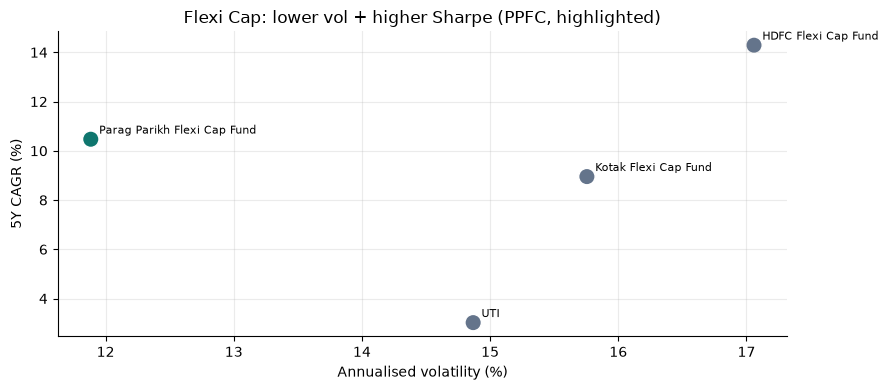

In [6]:
fig, ax = plt.subplots()
colors = ['#0f766e' if 'Parag' in n else '#64748b' for n in fx['name']]
ax.scatter(fx['vol'] * 100, fx['5Y'] * 100, s=140, c=colors, edgecolors='white')
for _, r in fx.iterrows():
    short = r['name'].split(' - ')[0]
    ax.annotate(short, (r['vol']*100, r['5Y']*100), xytext=(6, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel('Annualised volatility (%)')
ax.set_ylabel('5Y CAGR (%)')
ax.set_title('Flexi Cap: lower vol + higher Sharpe (PPFC, highlighted)')
plt.tight_layout(); plt.show()

## 3 — Mid-cap manager selection is worth 6.6 pp/year

Top-to-bottom 3Y CAGR gap in the Mid Cap category.

In [7]:
mc = df[df['category'] == 'mid_cap'].copy().sort_values('3Y', ascending=False)
display(mc[['name', '3Y', '5Y', 'vol', 'max_dd']].round(4))
gap_pp = (mc['3Y'].max() - mc['3Y'].min()) * 100
print(f'3Y CAGR gap (top vs bottom): {gap_pp:.2f} percentage points')

,name,3Y,5Y,vol,max_dd
18,Edelweiss Mid Cap Fund - Direct Plan - Growth,0.1818,0.1543,0.1715,-0.3921
14,HDFC Mid Cap Fund - Direct Plan - Growth,0.1527,0.1650,0.1559,-0.3951
17,Axis Midcap Fund - Direct Plan - Growth,0.1473,0.1107,0.1492,-0.2936
16,Kotak Mid Cap Fund - Direct Plan - Growth,0.1391,0.1382,0.1535,-0.3597
15,DSP Midcap Fund - Direct Plan - Growth,0.1154,0.0938,0.1613,-0.3272


3Y CAGR gap (top vs bottom): 6.64 percentage points


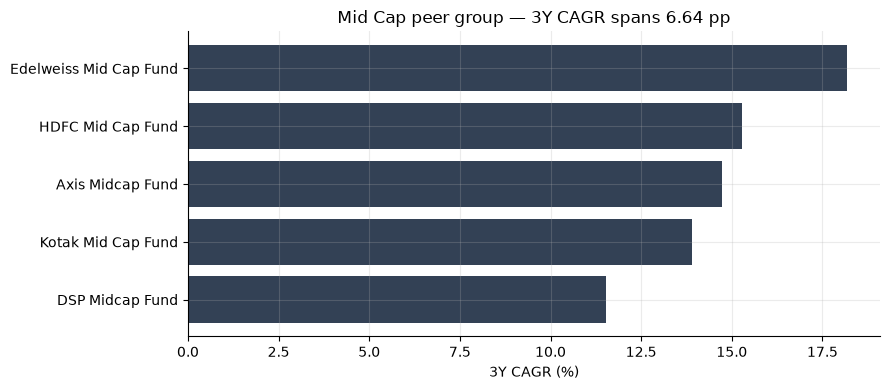

In [8]:
fig, ax = plt.subplots()
short = mc['name'].str.split(' - ').str[0]
ax.barh(short[::-1], (mc['3Y'] * 100)[::-1], color='#334155')
ax.set_xlabel('3Y CAGR (%)')
ax.set_title(f'Mid Cap peer group — 3Y CAGR spans {gap_pp:.2f} pp')
plt.tight_layout(); plt.show()

## 4 — Every small-cap fund has handed investors a 34–49% drawdown

The strong 5Y CAGR headline obscures the trough. Two of five funds nearly halved.

In [9]:
sc_df = df[df['category'] == 'small_cap'].copy().sort_values('max_dd')
display(sc_df[['name', '3Y', '5Y', 'max_dd']].round(4))
print(f'All 5 funds max_dd <= -34%? {(sc_df["max_dd"] <= -0.34).all()}')
print(f'5Y CAGR range: {sc_df["5Y"].min()*100:.2f}% - {sc_df["5Y"].max()*100:.2f}%')

,name,3Y,5Y,max_dd
25,DSP Small Cap Fund - Direct Plan - Growth,0.1542,0.1559,-0.4906
24,Nippon India Small Cap Fund - Direct Plan - Gr...,0.1262,0.1648,-0.4858
26,Kotak Small Cap Fund - Direct Plan - Growth,0.1020,0.1048,-0.4061
28,SBI SMALL CAP FUND - Direct Plan - Growth,0.0946,0.1134,-0.4026
27,Axis Small Cap Fund - Direct Plan - Growth,0.1290,0.1395,-0.3464


All 5 funds max_dd <= -34%? True
5Y CAGR range: 10.48% - 16.48%


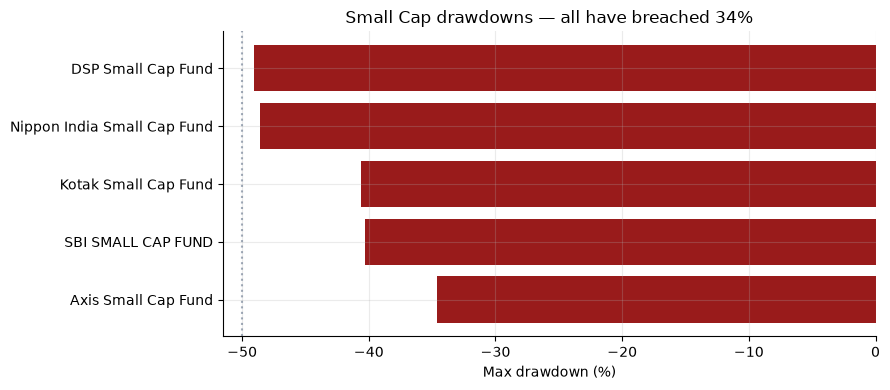

In [10]:
fig, ax = plt.subplots()
short = sc_df['name'].str.split(' - ').str[0]
ax.barh(short[::-1], (sc_df['max_dd'] * 100)[::-1], color='#991b1b')
ax.set_xlabel('Max drawdown (%)')
ax.axvline(-50, linestyle=':', color='#64748b', alpha=0.6)
ax.set_title('Small Cap drawdowns — all have breached 34%')
plt.tight_layout(); plt.show()

## 5 — Short-duration debt is flat; pick the lowest expense ratio

5Y CAGR spread across all 5 debt funds is 0.70 pp.

In [11]:
sd = df[df['category'] == 'short_debt'].copy().sort_values('5Y', ascending=False)
display(sd[['name', '1Y', '3Y', '5Y', 'vol', 'max_dd', 'sharpe']].round(4))
spread = (sd['5Y'].max() - sd['5Y'].min()) * 100
print(f'5Y CAGR spread: {spread:.2f} pp | vol spread: {(sd["vol"].max()-sd["vol"].min())*100:.2f} pp')

,name,1Y,3Y,5Y,vol,max_dd,sharpe
23,ICICI Prudential Short Term Fund - Direct Plan...,0.0483,0.0747,0.0696,0.0160,-0.0338,1.2719
20,Aditya Birla Sun Life Short Term Fund - Direct...,0.0452,0.0742,0.0672,0.0160,-0.0275,1.3015
22,Axis Short Term Fund - Direct Plan - Growth,0.0478,0.0759,0.0668,0.0146,-0.0260,1.1778
19,HDFC Short Term Fund - Direct Plan - Growth,0.0424,0.0722,0.0643,0.0134,-0.0267,1.1794
21,SBI SHORT TERM FUND - Direct Plan - Growth,0.0400,0.0706,0.0626,0.0137,-0.0235,0.9784


5Y CAGR spread: 0.70 pp | vol spread: 0.26 pp


## 6 — Only 5 of 20 active equity funds beat benchmark in every one of the last 5 years

Direct from the SQL query (`beats_benchmark_last_5y.sql`).

In [12]:
import sqlite3
sql = (REPO_ROOT / 'backend' / 'sql' / '02_beats_benchmark_last_5y.sql').read_text()
conn = sqlite3.connect(REPO_ROOT / 'data' / 'alphadesk.db')
beats = pd.read_sql_query(sql, conn)
display(beats[['scheme_code', 'name', 'category', 'benchmark_id', 'years_beaten']])
active = beats[beats['category'] != 'index']
equity_active = df[~df['category'].isin(['index', 'short_debt'])]
print(f'Active equity funds beating 5-for-5: {len(active)} of {len(equity_active)}')

,scheme_code,name,category,benchmark_id,years_beaten
0,118955,HDFC Flexi Cap Fund - Direct Plan - Growth,flexi_cap,NIFTY_50,5
1,120166,Kotak Flexi Cap Fund - Direct Plan - Growth,flexi_cap,NIFTY_50,5
2,118741,Nippon India Index Fund - Nifty 50 Plan - Dire...,index,NIFTY_50,5
3,119063,HDFC Nifty 50 Index Fund - Direct Plan - Growth,index,NIFTY_50,5
4,120716,UTI Nifty 50 Index Fund - Direct Plan - Growth,index,NIFTY_50,5
5,147622,Motilal Oswal Nifty Midcap 150 Index Fund - Di...,index,NIFTY_MIDCAP_150,5
6,119598,SBI Large Cap Fund - Direct Plan - Growth,large_cap,NIFTY_50,5
7,120586,ICICI Prudential Large Cap Fund (erstwhile Blu...,large_cap,NIFTY_50,5
8,118778,Nippon India Small Cap Fund - Direct Plan - Gr...,small_cap,NIFTY_SMALLCAP_250,5


Active equity funds beating 5-for-5: 5 of 20


### Appendix — March 2020 was the equity trough in every category

Running SQL #5 confirms the worst calendar month per category:

In [13]:
sql5 = (REPO_ROOT / 'backend' / 'sql' / '05_worst_drawdown_month_by_category.sql').read_text()
worst = pd.read_sql_query(sql5, conn)
display(worst[['category', 'year_month', 'cat_avg_return', 'cat_worst_fund_return']].round(4))

,category,year_month,cat_avg_return,cat_worst_fund_return
0,small_cap,2020-03,-0.2868,-0.3021
1,mid_cap,2020-03,-0.2493,-0.2746
2,index,2020-03,-0.2362,-0.2637
3,flexi_cap,2020-03,-0.2251,-0.2373
4,large_cap,2020-03,-0.2211,-0.2534
5,short_debt,2013-07,-0.0158,-0.0200
